In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
import ast 
from adjustText import adjust_text

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])

df = df.dropna(subset='salary_year_avg')

In [3]:
job_titles = df['job_title_short'].value_counts().nlargest(3).index.tolist()

In [7]:
df_india = df[df['job_country'] == 'India'].copy()

In [8]:
job_list = [df_india[df_india['job_title_short'] == job_title]['salary_year_avg'] for job_title in job_titles]

(0.0, 300000.0)

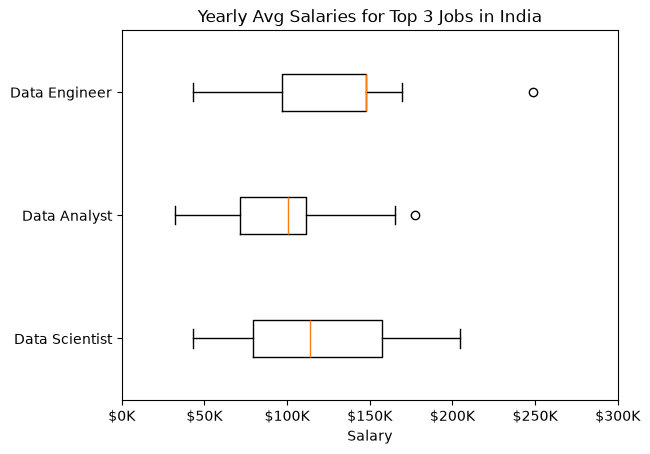

In [27]:
plt.boxplot(job_list, tick_labels = job_titles, orientation = 'horizontal')
ax = plt.gca()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos : f'${int(x/1000)}K'))
plt.title('Yearly Avg Salaries for Top 3 Jobs in India')
plt.xlabel('Salary')
plt.xlim(0, 300000)